# Árbol de decisión C4.5 contra Random Forest

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MaxDCoc/TPI_IA_2026/blob/main/notebooks/laboratorio_arboles_c45.ipynb)

**Inteligencia Artificial · 5.º nivel ISI · Ciclo lectivo 2026**

En este cuaderno se compara un **árbol de decisión C4.5**, programado íntegramente por el equipo sin usar librerías
de árboles, con el **Random Forest** de la librería scikit-learn. Los dos modelos se entrenan y se evalúan con los
mismos datos, para que la comparación sea justa.

| Objetivo de la consigna | Dónde se cumple |
|---|---|
| Implementar el algoritmo de árbol de decisión | El código está en `src/tp_ia/c45/` y se usa en las secciones 1 y 2. |
| Comparar el árbol con el Random Forest | En la interfaz, en la pestaña **Comparar**. |
| Analizar cómo cambian las métricas al modificar los parámetros | En la interfaz, en las pestañas **Árbol** y **Experimentos**. |

### Contenido

0. **Preparación:** descarga el código y las librerías necesarias.
1. **Interfaz interactiva:** permite usar todo el trabajo desde una sola pantalla, sin escribir código.
2. **El árbol desde código:** muestra cómo usar el mismo modelo directamente desde Python.
3. **Verificación:** ejecuta las pruebas automáticas del proyecto. Es opcional.

> **Cómo usarlo:** ejecutá las celdas en orden. En Colab, podés usar el menú *Entorno de ejecución → Ejecutar todas*.

## Preparación

Esta celda prepara todo lo necesario para que el cuaderno funcione. Si el cuaderno se abre dentro del repositorio,
usa ese mismo código. Si se abre en Colab, primero descarga el repositorio desde GitHub. En los dos casos, instala
[anywidget](https://anywidget.dev), la librería que permite mostrar la interfaz dentro del cuaderno.

In [1]:
# Prepara el entorno: usa el código local o, en Colab, clona el repositorio.
import os, subprocess, sys

REPO = "https://github.com/MaxDCoc/TPI_IA_2026.git"

def run_quiet(command, **kwargs):
    """Ejecuta un comando sin mostrar su salida; si falla, la muestra para poder ver qué pasó."""
    result = subprocess.run(command, capture_output=True, text=True, **kwargs)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:], sep="\n")
        raise RuntimeError("Falló el comando: " + " ".join(command))
    return result

if os.path.isdir("../src/tp_ia"):          # ejecución local, dentro del repositorio
    ROOT, ORIGIN = os.path.abspath(".."), "código local"
else:                                      # Colab: se clona
    if not os.path.isdir("TPI_IA_2026"):
        run_quiet(["git", "clone", "--depth", "1", REPO])
    ROOT, ORIGIN = os.path.abspath("TPI_IA_2026"), "clonado de GitHub"
run_quiet([sys.executable, "-m", "pip", "install", "-q", "anywidget"])
sys.path.insert(0, os.path.join(ROOT, "src"))
print(f"✔ Listo ({ORIGIN}): {ROOT}")

✔ Listo (código local): d:\Documentos\Facultad\inteligencia_artificial\tpi2026\TPI_IA_2026


## 1. Interfaz interactiva

La interfaz permite explorar los datos, entrenar el árbol, compararlo con el Random Forest y hacer experimentos,
todo sin escribir código. Los cálculos se hacen en Python y los resultados se dibujan en el navegador.

Al iniciar, la interfaz muestra el dataset de enfermedad cardíaca. Para usar otro, se elige en la lista de arriba a la derecha. También se puede cargar un archivo CSV propio desde la pestaña **Datos**.

### Conjuntos de datos disponibles

| Conjunto de datos | Qué contiene | Para qué sirve |
|---|---|---|
| **Enfermedad cardíaca** | 303 pacientes de la Cleveland Clinic, descritos con 13 atributos clínicos, como la edad, el colesterol o el tipo de dolor de pecho. | Es el dataset principal del trabajo: un problema real que mezcla atributos numéricos y nominales, y que tiene algunos valores faltantes. Se predice si el paciente tiene o no una enfermedad cardíaca. |
| **Play Tennis** | 14 días descritos por el clima. | Es el ejemplo clásico del libro de Quinlan, así que permite comparar el árbol obtenido con el del libro. |
| **Iris** | 150 flores de 3 especies, descritas con 4 medidas. | Es el dataset con el que se desarrolló y se probó el algoritmo. |
| **Wine** | 178 vinos de 3 variedades, descritos con 13 atributos químicos. | Muestra cómo se comportan los modelos cuando hay más atributos. |
| **Breast Cancer Wisconsin** | 569 casos con 30 medidas, clasificados en 2 diagnósticos. | Es otro caso real, más exigente por la cantidad de atributos. |

> En el dataset de enfermedad cardíaca, los atributos tienen nombres en español y sus códigos se reemplazaron por su significado (por ejemplo, *sin síntomas* en lugar de *4*). Así el árbol se puede leer sin consultar un diccionario. En la pestaña **Datos**, cada atributo muestra una breve explicación de lo que mide.

| Pestaña | Qué se puede hacer |
|---|---|
| **1. Datos** | Ver el conjunto de datos elegido: sus atributos, la calidad de los datos y las decisiones que se tomaron sobre ellos. |
| **2. Árbol** | Ver el árbol C4.5 dibujado. Al cambiar los parámetros, el árbol se vuelve a entrenar al instante. También se puede describir un caso y ver qué clase predice cada modelo. |
| **3. Comparar** | Comparar el árbol con el Random Forest sobre las mismas particiones de los datos, con el promedio y el desvío de cada métrica. |
| **4. Experimentos** | Probar varios valores de un parámetro para ver cuándo aparece el sobreajuste, y medir qué pasa cuando faltan datos. |

### Recorrido sugerido

1. **Datos:** con *Enfermedad cardíaca*, que es el dataset que se muestra al iniciar, leé qué mide cada atributo y fijate, por los colores de las barras, qué valores aparecen más en los pacientes con enfermedad.
2. **Árbol:** activá *Podar por error pesimista* y compará la cantidad de nodos y la exactitud antes y después de podar.
3. **Árbol:** en *Predecir un caso*, mové los valores. Después marcá un atributo como *falta* y fijate cómo el árbol reparte el caso entre las ramas.
4. **Comparar:** tocá **Comparar** con los valores que propone la cátedra (100 árboles y profundidad 10).
5. **Experimentos:** probá distintos valores de *Profundidad máxima*, del 1 al 8, y buscá a partir de cuál el árbol empieza a sobreajustar.

In [2]:
# Abre la interfaz interactiva.
from tp_ia.web.widget import show

lab = show()

## 2. El árbol desde código

Esta sección entrena el árbol C4.5 directamente desde Python, sin pasar por la interfaz, y cumple dos funciones.
La primera es mostrar que la implementación es una clase que se puede usar en cualquier programa: se crea el árbol,
se lo entrena con `fit` y queda listo para predecir. La segunda es que el resultado queda guardado en el cuaderno,
así que el árbol se puede ver aunque el cuaderno no se ejecute, por ejemplo al abrirlo en GitHub, donde la interfaz
no aparece.

Se usa el dataset de enfermedad cardíaca con la poda activada y la misma partición que usa la interfaz al iniciar:
el 70 % de los pacientes para entrenar y el 30 % restante para medir la exactitud con casos que el árbol no vio.
Por eso el árbol que aparece acá es idéntico al de la pestaña **Árbol** con la poda activada. Para probar otros
parámetros o consultar las decisiones sobre los datos conviene usar la interfaz, porque las pestañas **Árbol** y
**Datos** muestran esa información de forma interactiva.

Entrenado con 212 pacientes y evaluado con 91.
39 nodos (se podaron 12), profundidad 7
Exactitud con los datos de prueba: 79.1%


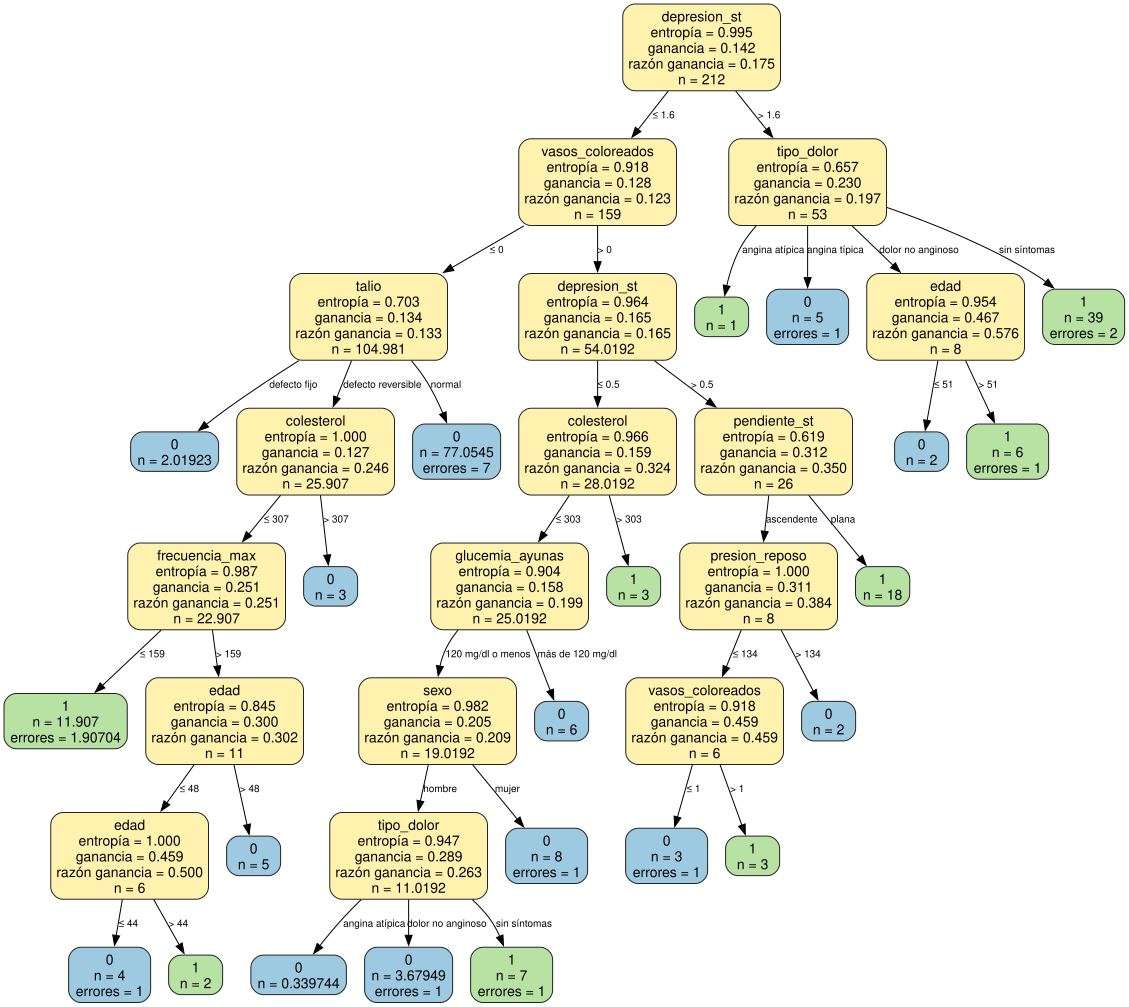

In [3]:
# Entrena el árbol propio con poda sobre el dataset de enfermedad cardíaca y lo dibuja con Graphviz,
# con el formato de las láminas de la cátedra.
from IPython.display import SVG, display
from tp_ia.c45 import C45DecisionTree
from tp_ia.data import load_heart_dataset
from tp_ia.eval import make_splits

ds = load_heart_dataset()

# La misma partición que la interfaz: 70 % para entrenar y 30 % para evaluar, estratificada y con la semilla 0.
split = make_splits(ds.y, scheme="holdout", n_repeats=1, test_size=0.3, seed=0)[0]
y = ds.y.to_numpy()
X_train, y_train = ds.X.iloc[split.train], y[split.train]
X_test, y_test = ds.X.iloc[split.test], y[split.test]

tree = C45DecisionTree(prune=True).fit(X_train, y_train, feature_types=ds.feature_types)
print(f"Entrenado con {len(y_train)} pacientes y evaluado con {len(y_test)}.")
print(f"{tree.n_nodes_} nodos (se podaron {tree.n_pruned_}), profundidad {tree.depth_}")
print(f"Exactitud con los datos de prueba: {tree.score(X_test, y_test):.1%}")

try:    # se dibuja acá mismo para que un error de Graphviz se pueda atrapar y explicar
    from graphviz import Source
    display(SVG(Source(tree.to_dot()).pipe(format="svg").decode("utf-8")))
except Exception as error:
    print("\nNo se pudo dibujar con Graphviz:", error)
    print("Hace falta tener instalado Graphviz. Mientras tanto, el árbol se puede ver como texto con print(tree.export_text()).")

## 3. Verificación (opcional)

Esta celda ejecuta las pruebas automáticas del proyecto. Las pruebas comprueban que funcionen correctamente el
algoritmo C4.5, la carga de los datos, la evaluación de los modelos y la interfaz.

In [5]:
# Corre las pruebas automáticas del proyecto y muestra solo el resumen (o el detalle, si algo falla).
run_quiet([sys.executable, "-m", "pip", "install", "-q", "pytest"])
result = subprocess.run([sys.executable, "-m", "pytest", "--color=no", "-p", "no:cacheprovider"],
                        cwd=ROOT, capture_output=True, text=True)
summary = result.stdout.strip().splitlines()
if result.returncode == 0:
    print("✔", summary[-1])
else:
    print(result.stdout[-4000:] or result.stderr[-4000:])

✔ 141 passed in 19.58s
